# Phase 1: Support-set study on V2

## Section 1 - Purpose and overview

This study chooses the reference frames of V2, the support set. V2 classifies each patch by its nearest labelled reference patch (multi-prototype study, Section 8). With background margin 0 (margin study, Section 9) it is the current method of perception.

The support set of V2 has 10 frames, all chosen while the method was V0, one mean prototype per class. Eight come from the support-set study, where more frames helped V0 little: a frame aimed at a rare appearance brings only a few patches and barely moves the mean (support-set study, Sections 6.1 and 8). Two were added in the multi-prototype study by a coverage rule: for each piece, at least one example of each state in which it appears during the assembly (multi-prototype study, Section 1). Those two frames were motivated by errors seen on the validation set (multi-prototype study, Section 8). V2 keeps every labelled patch as a prototype, so a single frame with a missing appearance can change its predictions (Mensink et al. 2013, Sect. 1). The frames of the support set have never been chosen for V2.

Several limits of V2 are known from the previous studies. A loose arm is missed or confused near the hands. The hat is often missed on the table and in the hand. The mouth is recognized well only when its front is visible; seen from the side, its pin is predicted as nose. Hat patches appear in the cavity of the base when the base is alone. There are false positives on the watch, and on objects never seen.

An exploration suggests that the frames of the support set are the main lever. With the two frames of 1_disassembled_controlled_caos added to the support set, the loose arm on the table is seen in 44% of the frames of the assembly_2 video instead of 12%, and the hat in 67% instead of 54% (scratch_support_swap.ipynb). This result is optimistic: those two frames were validation frames, and the video was used for exploration. It is a hypothesis to test, not a result.

The study looks ahead to Phase 2. State tracking needs to know, for every piece, whether it is on the table, in a hand or mounted. A wrong pick is signalled before the error, a wrong mounting when it happens. Perception is therefore evaluated separately in three moments: pieces at rest on the table, the pick, and the mounting.

A piece needs a new example in the support set only when it looks clearly different. For the pieces of this toy, two appearances differ: loose, where the whole piece is visible with its pin, back and sides, and mounted, where only its front is visible and it is attached to another piece. Smaller changes, such as the angle of view, the grip of a hand, a glove or bare skin, are variations of appearance that the frozen features are expected to absorb. Whether they do is measured, not assumed (Section 6). Hands are treated as an attribute, like occlusion in PASCAL VOC, where the viewpoint of an object is an annotated attribute and occlusion a separate flag (Everingham et al. 2010, Sect. 3.3). A pick is therefore not a third state: the pieces are covered loose and mounted, and the frames with hands show them partly covered. The mouth must be recognized in both states, from the moment it lies on the table.

The support set is chosen by decremental prototype selection. A nearest neighbour classifier must store all its examples, and prototype selection looks for a smaller subset that classifies as well as the whole set (García et al. 2012, Sect. 1). Hart defined a consistent subset as one that classifies correctly all the remaining examples, and a minimal consistent subset as the smallest one (Hart 1968, p. 515). Gates reduced a consistent subset by removing one example at a time and putting it back if any example was then misclassified; he showed that this finds the minimal consistent subset whenever the starting set contains it (Gates 1972, pp. 432-433). An incremental search, which adds examples, decides with little information; a decremental search, which removes them, has all the data at hand and can reduce more (García et al. 2012, Sect. 3.1.1). Here the decision is checked by cross-validation, the wrapper evaluation of García et al. (Sect. 3.1.3).

Three adaptations are needed. The unit removed is a whole frame, because the cost is the annotated frame. A frame may be removed only if every state it covers stays covered by another frame. And since patches are never all classified correctly, the condition "no example misclassified" becomes a tolerance on the cross-validated mIoU, justified in Section 6.

A decremental search can only remove, so the starting set must contain every appearance needed. The candidates therefore follow no rule of their own: they only have to cover both states of every piece. They are the 10 frames of the current support set, now with every annotated class of caos_f0211 and caos_f0043; the two frames of 1_disassembled_controlled_caos; and caos_f0278, the first frame of the caos recording that shows the complete figure from the front, at working distance, with no hand covering it. Before this study, the mounted pieces were seen almost only from far away.

The validation set changes. It now contains only frames of assembly_2: the 6 frames used so far and 26 new frames, chosen from the event log and the raw video by rules fixed before any result was seen (Section 3). The test recording, assembly_1, is not read, and is used once at the end of Phase 1. Splits are made by recording, as in Assembly101 (Sener et al. 2022, Sect. 4.6).

Choices made on the validation set make its results optimistic, more so with few frames and many variants (Cawley and Talbot 2010, Sect. 4.4 and 5). The support set is therefore chosen without the validation set, on the candidates only (Section 6), and the validation set is used once, by a decision rule written before it is run (Section 8). The rule is added to this section before Section 8 is run.

The study is organized as follows. Section 2 sets the configuration. Section 3 builds and checks the new validation set. Section 4 checks that the current V2 reproduces the margin study. Section 5 lists the two states of every piece and the candidates that cover them. Section 6 removes the redundant candidates, and Section 7 sets the background margin of the result. Section 8 applies the decision rule. Section 9 looks at continuous perception on assembly_2, as an exploration. Section 10 gives the decision and the conclusions.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Mensink et al. 2013, Sect. 1: the nearest neighbour classifier keeps every training example, while a class mean summarizes them.

Everingham et al. 2010, Sect. 3.3: the viewpoint of each object is annotated as an attribute, and occlusion as a separate flag.

Hart 1968, p. 515: definition of consistent and minimal consistent subset; the condensed nearest neighbour rule finds a consistent subset, in general not a minimal one.

Gates 1972, pp. 432-433: the reduced nearest neighbour rule removes one example at a time and keeps the removal only if every example is still classified correctly; it finds the minimal consistent subset when the starting set contains it.

García et al. 2012, Sect. 1: prototype selection reduces the stored set of a nearest neighbour classifier. Sect. 3.1.1: incremental and decremental search. Sect. 3.1.3: filter and wrapper evaluation.

Sener et al. 2022, Assembly101, Sect. 4.6: training, validation and test splits are made by video, and the test ground truth is withheld.

Cawley and Talbot 2010, Sect. 4.4: selecting by optimizing a criterion on a finite sample over-fits, more with small samples and many choices. Sect. 5: a performance estimate on the data used for selection is optimistically biased.

Previous studies: support-set study (v1.3), Sections 6.1 and 8; multi-prototype study (v1.5), Sections 1 and 8; margin study (v1.6), Section 9; scratch_support_swap.ipynb (exploratory, not part of any study).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, frames and hyperparameters in one place. The values are those of the margin study (Section 2): V2 on the same 10 reference frames, with the background margin decided there, 0. Three things change.

The validation set contains only assembly_2: the 6 frames used so far and the 26 new frames, 32 in all, each with its moment (table, pick or mount) and its piece. The rules that chose them are given and checked in Section 3. The frames are listed in time order, the order of the video.

The candidates for the support set are listed here (Section 1): the 10 frames of the current support set, with every annotated class, the two frames of 1_disassembled_controlled_caos, and caos_f0278. Their annotations are the current ones; caos_f0211 was completed for this study. The current support set keeps the annotations used by the margin study, so that Section 4 can reproduce it; the old annotation of caos_f0211 is kept in data/annotation_versions/margin_study.

The 8 validation frames of the margin study are kept as a separate list, used only to check in Section 4 that the current V2 reproduces that study.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
%load_ext autoreload
%autoreload 2

import sys
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from PIL import Image
from scipy import ndimage

In [3]:
# 2.3 Paths and shared module
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_2.mp4"                # Sections 3 and 9
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_2_events.json"                   # Sections 3 and 9
MARGIN_STUDY_DIR = PROJECT_ROOT / "outputs" / "phase_1_margin_study"                # decision and labels of the margin study (Section 4)
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_support_set_v2_study"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATION_ARCHIVE = PROJECT_ROOT / "data" / "annotation_versions" / "margin_study"   # annotations as used by the margin study

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "VIDEO_PATH": VIDEO_PATH, "EVENTS_PATH": EVENTS_PATH,
                   "margin study decision": MARGIN_STUDY_DIR / "decision.json",
                   "annotation archive (margin study)": ANNOTATION_ARCHIVE / "caos_f0211.json"}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Decision of the margin study (Section 9), printed so that this notebook records what it starts from
print("\nMargin study decision:")
print(json.dumps(json.loads((MARGIN_STUDY_DIR / "decision.json").read_text()), indent=2))

# Shared code (src/perception)
from perception.classes import CLASS_NAMES, BACKGROUND_ID, HAND_LABEL, PIECE_LABELS, IGNORE_ID, PATCH_LABEL_NAMES, CLASS_COLORS
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels, l2_normalize)
from perception.metrics import (confusion_matrix, iou_from_confusions, mean_iou, ignore_boundary_ring,
                                MERGED_NAMES, MERGED_PIECES, merge_arms, merged_ids,
                                frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou, percentile_interval)
from perception.visualization import label_grid_to_rgb, render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] VIDEO_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\assembly_2.mp4
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_2_events.json
[OK] margin study decision: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_margin_study\decision.json
[OK] annotation archive (margin study): c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\annotation_versions\margin_study\caos_f0211.json

Margin study decision:
{
  "variant": "V2",
  "background_margin": 0.0,
  "decided_margin": {
    "V0": 0.15499374270439148,
    "V2": 0.0
  },
  "m_star_cross_validation": {
    "V0": 0.15499374270439148,
    "V2": 0.020618915557861328
  },
  "m_star_bootstrap_95": {
    "V0"

Observation 2.3: The margin study decided V2 with background margin 0, on the same 10 reference frames, in the same order as CURRENT_SUPPORT. Its decision notes that the margin holds only for that support set. With a new support set the margin is chosen again (Section 7).

In [4]:
# 2.4 Hyperparameters
# Same values as the margin study (Section 2.4), with the margin decided there for V2 (Section 9).

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16          # input resolution: native 1024x1024 (resolution study)

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5        # same rule as the pipeline (Section 5)

# --- Classification ---
MARGIN = 0.0                    # background margin of V2, decided in the margin study (Section 9): each patch takes its most similar class

# --- Evaluation ---
N_BOOTSTRAP = 1000              # resamples of the frames (support-set study, Section 5.4)
BOUNDARY_RING = 1               # secondary metric: background patches within 1 patch of an object are ignored

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: assembly_2 only, used once, by the decision rule (Section 8).
# Test: held out until the end of Phase 1. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Current support set: the 10 frames of the multi-prototype and margin studies, in the same order (margin study, Section 2.5),
# with the annotations used there. caos_f0211 was completed for this study, so its old annotation is read from the archive.
CURRENT_SUPPORT = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL},
     "json_path": ANNOTATION_ARCHIVE / "caos_f0211.json"},
    {"frame": "4_partially_assembled_f0002",  "role": "body on base, face incomplete (empty mouth slot); mouth loose at 3/4",
     "use_labels": {"body", "mouth"}},
    {"frame": "caos_f0043",                   "role": "mouth loose, side view",      "use_labels": {"mouth"}},
]

# Candidates (Section 1): every annotated class, with the current annotations.
# Base stays out of the disassembled frames, where it is split into pants and shoes (legacy labels), as in the previous studies.
DISASSEMBLED = {"3_disassembled_ordered", "2_disassembled_caos", "1_disassembled_controlled_caos"}
_CANDIDATES = [
    "5_assembled_f0002", "5_assembled_f0019", "caos_f0149", "caos_f0211", "caos_f0043", "caos_f0278",
    "3_disassembled_ordered_f0001", "2_disassembled_caos_f0016",
    "1_disassembled_controlled_caos_f0001", "1_disassembled_controlled_caos_f0016",
    "Take_3_1_Base_f0099", "Take_3_1_Base_f0131", "4_partially_assembled_f0002",
]
CANDIDATES = [{"frame": frame,
               "use_labels": (PIECE_LABELS | {HAND_LABEL}) - ({"base"} if sequence_of(frame) in DISASSEMBLED else set())}
              for frame in _CANDIDATES]

# Validation: 32 frames of assembly_2 in time order. moment = table, pick or mount (rules in Section 3).
# For pick and mount, piece is the piece being picked or mounted; for table, the state of the figure.
# old = one of the 6 frames used since the support-set study.
_VALIDATION = [
    (3,  "table", None,           "all pieces loose",                     True),
    (4,  "pick",  "base",         "base just picked",                     False),
    (5,  "mount", "base",         "base placed at the work position",     False),
    (8,  "table", None,           "base alone at the work position",      False),
    (10, "pick",  "body",         "body touched, hand mostly outside",    False),
    (12, "mount", "body",         "body put on the base",                 False),
    (17, "table", None,           "body on base, mouth not yet picked",   True),
    (18, "pick",  "mouth",        "mouth touched",                        False),
    (19, "mount", "mouth",        "pin of the mouth at the slot",         False),
    (24, "table", None,           "mouth mounted",                        False),
    (26, "pick",  "moustache",    "moustache picked",                     False),
    (28, "pick",  "nose",         "nose touched, moustache in the other hand", False),
    (30, "mount", "nose",         "nose threaded into the moustache, in hand", True),
    (33, "mount", "nose+moustache", "nose and moustache entering the slot", False),
    (37, "table", None,           "nose and moustache mounted",           False),
    (42, "pick",  "eyes",         "hand on the eyes",                     False),
    (43, "mount", "eyes",         "eyes entering the slot",               False),
    (46, "table", None,           "face complete, ears loose",            True),
    (50, "pick",  "ear",          "ear (image right) in hand",            False),
    (51, "mount", "ear",          "ear (image right) on the head",        False),
    (52, "table", None,           "one ear mounted, hands in view",       False),
    (53, "pick",  "ear",          "ear (image left) in hand",             False),
    (54, "mount", "ear",          "ear (image left) being pushed in",     False),
    (57, "table", None,           "ears mounted, arms loose",             True),
    (59, "pick",  "arm_1",        "arm_1 just picked, far from the body", False),
    (60, "mount", "arm_1",        "arm_1 touching its hole",              False),
    (63, "pick",  "arm_2",        "arm_2 just picked, far from the body", False),
    (65, "mount", "arm_2",        "arm_2 in its hole, hand on it",        False),
    (68, "table", None,           "arms mounted, hat loose",              True),
    (70, "pick",  "hat",          "hat in hand",                          False),
    (73, "mount", "hat",          "hat entering the head",                False),
    (77, "table", None,           "figure complete, hands still",         False),
]
VALIDATION_FRAMES = [{"frame": f"assembly_2_f{index:04d}", "index": index, "moment": moment, "piece": piece,
                      "note": note, "old": old} for index, moment, piece, note, old in _VALIDATION]
EXCLUDED = [set() for _ in VALIDATION_FRAMES]   # no class is out of definition on assembly_2 frames

# Validation of the margin study (Section 2.5): used only for the regression check of Section 4
MARGIN_STUDY_VALIDATION = [
    {"frame": "assembly_2_f0003"}, {"frame": "assembly_2_f0017"}, {"frame": "assembly_2_f0030"},
    {"frame": "assembly_2_f0046"}, {"frame": "assembly_2_f0057"}, {"frame": "assembly_2_f0068"},
    {"frame": "1_disassembled_controlled_caos_f0001", "exclude": {"base"}},
    {"frame": "1_disassembled_controlled_caos_f0016", "exclude": {"base"}},
]

# Checks: no leakage, every file present, the planned composition
for item in CURRENT_SUPPORT + CANDIDATES:
    assert sequence_of(item["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {item['frame']}"
    item["image_path"] = frame_path(item["frame"])
    item["json_path"] = item.get("json_path") or frame_path(item["frame"], ".json")
    assert item["image_path"].exists() and item["json_path"].exists(), f"Missing files: {item['frame']}"
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    val["image_path"], val["json_path"] = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    assert val["image_path"].exists() and val["json_path"].exists(), f"Missing files: {val['frame']}"
indices = [val["index"] for val in VALIDATION_FRAMES]
assert indices == sorted(set(indices)), "Validation frames must be unique and in time order"
assert sum(val["old"] for val in VALIDATION_FRAMES) == 6
assert {v["frame"] for v in MARGIN_STUDY_VALIDATION[:6]} == {v["frame"] for v in VALIDATION_FRAMES if v["old"]}

GT_LABELS = PIECE_LABELS | {HAND_LABEL}   # validation ground truth: every official class; legacy labels become ignored

composition = pd.crosstab(pd.Series([v["moment"] for v in VALIDATION_FRAMES], name="moment"),
                          pd.Series(["old" if v["old"] else "new" for v in VALIDATION_FRAMES], name="frames"),
                          margins=True, margins_name="total")
print(f"{len(CURRENT_SUPPORT)} reference frames, {len(CANDIDATES)} candidates, {len(VALIDATION_FRAMES)} validation frames")
display(composition)
display(pd.DataFrame(VALIDATION_FRAMES).set_index("frame")[["moment", "piece", "note", "old"]])

10 reference frames, 13 candidates, 32 validation frames


frames,new,old,total
moment,,,
mount,10,1,11
pick,11,0,11
table,5,5,10
total,26,6,32


,moment,piece,note,old
frame,,,,
assembly_2_f0003,table,None,all pieces loose,True
assembly_2_f0004,pick,base,base just picked,False
assembly_2_f0005,mount,base,base placed at the work position,False
assembly_2_f0008,table,None,base alone at the work position,False
assembly_2_f0010,pick,body,"body touched, hand mostly outside",False
assembly_2_f0012,mount,body,body put on the base,False
assembly_2_f0017,table,None,"body on base, mouth not yet picked",True
assembly_2_f0018,pick,mouth,mouth touched,False
assembly_2_f0019,mount,mouth,pin of the mouth at the slot,False


Observation 2.5: The study starts from 10 reference frames, the current support set, and 13 candidates: those 10 frames with every annotated class, the two frames of 1_disassembled_controlled_caos and caos_f0278. The validation set has 32 frames: 10 table frames, 5 old and 5 new, 11 pick frames, all new, and 11 mount frames, 10 new and 1 old.

Five of the 6 old frames are table frames. The sixth, assembly_2_f0030, was described in the previous studies as a piece held in hand; with the rules of Section 3 it is a mounting, the nose threaded into the moustache in the hand. Before this study the validation set had no pick frame.

In [6]:
# 2.6 Annotation fingerprints: data/ is not tracked by git, so the notebook records which annotations it used.
# Fingerprints recorded by the margin study (Section 2.6), to check that the files it used are unchanged.
MARGIN_STUDY_SHA = {
    "5_assembled_f0002": "e85d1c179582", "caos_f0149": "14f88d7cf080", "5_assembled_f0019": "1cd8cdcc2c9b",
    "3_disassembled_ordered_f0001": "319c3601f0a1", "2_disassembled_caos_f0016": "f17ab6af8218",
    "Take_3_1_Base_f0099": "853e60024c17", "Take_3_1_Base_f0131": "f07f67aae3a9", "caos_f0211": "3c56b4804e54",
    "4_partially_assembled_f0002": "32a94339f2b4", "caos_f0043": "3b555dd93c2c",
    "assembly_2_f0003": "350cee9c49e9", "assembly_2_f0017": "ce242dfd4544", "assembly_2_f0030": "69a762c4d37d",
    "assembly_2_f0046": "63664e7faa10", "assembly_2_f0057": "7bf765f2fda9", "assembly_2_f0068": "326615769d7c",
    "1_disassembled_controlled_caos_f0001": "6ba5febd2141", "1_disassembled_controlled_caos_f0016": "1d3db54d65ad",
}


def fingerprint(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]


rows = ([(item["frame"], "current support", item["json_path"]) for item in CURRENT_SUPPORT]
        + [(item["frame"], "candidate", item["json_path"]) for item in CANDIDATES]
        + [(val["frame"], f"validation ({val['moment']})", val["json_path"]) for val in VALIDATION_FRAMES])
fingerprints = pd.DataFrame([{"frame": frame, "set": role, "annotation sha256": fingerprint(path),
                              "margin study": ("new" if frame not in MARGIN_STUDY_SHA
                                               else "same" if fingerprint(path) == MARGIN_STUDY_SHA[frame] else "CHANGED")}
                             for frame, role, path in rows]).set_index("frame")
display(fingerprints)
print(fingerprints["margin study"].value_counts().to_string())

,set,annotation sha256,margin study
frame,,,
5_assembled_f0002,current support,e85d1c179582,same
caos_f0149,current support,14f88d7cf080,same
5_assembled_f0019,current support,1cd8cdcc2c9b,same
3_disassembled_ordered_f0001,current support,319c3601f0a1,same
2_disassembled_caos_f0016,current support,f17ab6af8218,same
Take_3_1_Base_f0099,current support,853e60024c17,same
Take_3_1_Base_f0131,current support,f07f67aae3a9,same
caos_f0211,current support,3c56b4804e54,same
4_partially_assembled_f0002,current support,32a94339f2b4,same


margin study
same       27
new        27
CHANGED     1


Observation 2.6: The current support set reads the annotations used by the margin study: all 10 have the fingerprints recorded there (margin study, Section 2.6), caos_f0211 through its archived copy. Among the candidates, 11 annotations are unchanged, caos_f0278 is new, and caos_f0211 is CHANGED: it was completed for this study, with the base relabelled from the legacy labels pants and shoe, both arms added, and the body limited to its visible part around the fingers. The 6 old validation frames are unchanged and the 26 new ones have new fingerprints, 27 same, 1 changed and 27 new in all.

In [7]:
# 2.7 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The values and the current support set are those of the margin study (Sections 2.4, 2.5 and 9); the validation frames are chosen by the rules of Section 3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - The new validation set

This section builds the new validation set and checks it before any prediction is made on it.

The 32 frames come from assembly_2 and lie on the grid of extracted frames, one every 30 video frames: frame fNNNN is video frame 30 x NNNN (extract_frames.py). Every frame belongs to one of three moments, and each moment has its rule. The rules were applied by looking at the extracted frames and at the raw video, never at the output of the model.

Pick. The first extracted frame in which the hand touches the piece, in the contact that ends with the piece lifted. Touches that do not lift the piece are not counted.

Mount. The first extracted frame in which the piece touches the part it is mounted on. The intermediate assembly of nose and moustache in the hand counts as a mounting.

Table. In each pause between two picks, the extracted frame closest to the centre of the pause in which no hand touches a piece. Hands may be in view. A pause that already contains one of the 6 old frames is covered by it. A pick that is put back, like the ear lifted and put down before the eyes, ends a pause like any other pick.

Contacts are judged on the raw video at 30 fps and on the extracted frames. The frame is always chosen among the extracted frames, and a chosen frame is never replaced because of how it looks.

The event log of assembly_2 records, for every piece, the first contact of the hand (touch), the first contact with the part it is mounted on (insert) and the moment the hands leave the figure (hands_off), with notes for touches without lifting and for the ear put back. It was revised on the raw video for this study, after perception outputs on this video had been seen, with these definitions; the fields used by the previous studies did not change (configs/assembly_2_events.json, field revision). Section 3.1 recomputes the 32 frames from the log with the three rules and compares them with the list of Section 2.5. This checks that the list follows the rules given the log; it does not check the contacts themselves, which were judged by eye.

Section 3.2 checks the annotation files. Section 3.3 builds the ground truth of every frame and shows it on four frames chosen before looking. Section 3.4 counts what the validation set contains, piece by piece and moment by moment.

In [8]:
# 3.1 The three rules recomputed from the event log, and compared with the list of Section 2.5
from perception.classes import LEGACY_LABELS

EVENT_LOG = json.loads(EVENTS_PATH.read_text())
EVENTS, NOTES = EVENT_LOG["events"], EVENT_LOG["notes"]
GRID = 30                                    # one extracted frame every 30 video frames (extract_frames.py)


def notes_with(text):
    """Frame intervals of the notes whose description contains text."""
    return [note["frames"] for note in NOTES if text in note["what"]]


def event_of(val):
    """Event of the piece picked or mounted in a validation frame (ear: the side written in the note)."""
    piece = "nose" if val["piece"] == "nose+moustache" else val["piece"]
    found = [e for e in EVENTS if e["piece"] == piece and (piece != "ear" or e["side"] in val["note"])]
    assert len(found) == 1, f"No single event for {val['frame']}"
    return found[0]


(JOIN,) = notes_with("threaded into the moustache")           # nose into moustache, in hand: [first contact, fully joined]
(PUT_BACK,) = notes_with("put back")                         # the ear picked and put back: a pick that ends a pause
NO_LIFT = notes_with("without lifting")                      # touches without lifting: no pause ends, but no table frame either
(HEAD_TURN,) = notes_with("head turns")
END_OF_ASSEMBLY = HEAD_TURN[0]                               # last pause ends when the head turns to the monitor


def first_from(start, t):
    """t is the first extracted frame at or after start."""
    return t >= start and t - GRID < start


# Pick and mount: each frame against its rule
rows = []
for val in VALIDATION_FRAMES:
    t = GRID * val["index"]
    if val["moment"] == "pick":
        e = event_of(val)
        window, ok = (e["touch"], e["insert"]), first_from(e["touch"], t) and t < e["insert"]
    elif val["moment"] == "mount" and "threaded" in val["note"]:
        window, ok = tuple(JOIN), first_from(JOIN[0], t)
    elif val["moment"] == "mount":
        e = event_of(val)
        window, ok = (e["insert"], e["hands_off"]), first_from(e["insert"], t) and t < e["hands_off"]
    else:
        continue
    rows.append({"frame": val["frame"], "moment": val["moment"], "piece": val["piece"], "video frame": t,
                 "window": f"{window[0]}-{window[1]}", "rule satisfied": ok})
picks_mounts = pd.DataFrame(rows).set_index("frame")
display(picks_mounts)

# Table: pauses between picks, from the log
busy = sorted([(e["touch"], e["hands_off"]) for e in EVENTS] + [tuple(PUT_BACK)])
merged = []
for start, end in busy:
    if merged and start <= merged[-1][1]:
        merged[-1] = (merged[-1][0], max(merged[-1][1], end))
    else:
        merged.append((start, end))
pauses, previous_end = [], -1
for start, end in merged:
    pauses.append((previous_end + 1, start - 1))
    previous_end = end
pauses.append((previous_end + 1, END_OF_ASSEMBLY))

old_indices = {val["index"] for val in VALIDATION_FRAMES if val["old"]}
rows, expected_table = [], set()
for start, end in pauses:
    grid = [k for k in range(start // GRID, end // GRID + 1)
            if start <= GRID * k <= end and not any(a <= GRID * k <= b for a, b in NO_LIFT)]
    old = [k for k in grid if k in old_indices]
    centre = (start + end) / 2
    chosen = old[0] if old else (min(grid, key=lambda k: abs(GRID * k - centre)) if grid else None)
    if chosen is not None:
        expected_table.add(chosen)
    rows.append({"pause": f"{start}-{end}", "centre": centre, "extracted frames": len(grid),
                 "chosen": "-" if chosen is None else f"f{chosen:04d}", "covered by an old frame": bool(old)})
display(pd.DataFrame(rows))

listed_table = {val["index"] for val in VALIDATION_FRAMES if val["moment"] == "table"}
print(f"Pick and mount frames that satisfy their rule: {picks_mounts['rule satisfied'].sum()} of {len(picks_mounts)}")
print(f"Table frames recomputed from the log: {sorted(expected_table)}")
print(f"Table frames listed in Section 2.5:   {sorted(listed_table)}")
assert picks_mounts["rule satisfied"].all() and expected_table == listed_table

,moment,piece,video frame,window,rule satisfied
frame,,,,,
assembly_2_f0004,pick,base,120,110-132,True
assembly_2_f0005,mount,base,150,132-168,True
assembly_2_f0010,pick,body,300,287-334,True
assembly_2_f0012,mount,body,360,334-425,True
assembly_2_f0018,pick,mouth,540,538-568,True
assembly_2_f0019,mount,mouth,570,568-640,True
assembly_2_f0026,pick,moustache,780,774-987,True
assembly_2_f0028,pick,nose,840,832-987,True
assembly_2_f0030,mount,nose,900,880-930,True


,pause,centre,extracted frames,chosen,covered by an old frame
0,0-109,54.5,4,f0003,True
1,169-286,227.5,4,f0008,False
2,426-537,481.5,3,f0017,True
3,641-773,707.0,3,f0024,False
4,1031-1165,1098.0,4,f0037,False
5,1251-1255,1253.0,0,-,False
6,1329-1479,1404.0,4,f0046,True
7,1559-1563,1561.0,1,f0052,False
8,1653-1752,1702.5,3,f0057,True
9,1876-1881,1878.5,0,-,False


Pick and mount frames that satisfy their rule: 22 of 22
Table frames recomputed from the log: [3, 8, 17, 24, 37, 46, 52, 57, 68, 77]
Table frames listed in Section 2.5:   [3, 8, 17, 24, 37, 46, 52, 57, 68, 77]


Observation 3.1: All 22 pick and mount frames satisfy their rule against the event log. Each is the first extracted frame at or after the touch or the insert of its piece, and comes before the next event of that piece. The nose threaded into the moustache, assembly_2_f0030, falls in the interval 880-930 of the log.

The log gives 12 pauses between picks. Ten contain at least one extracted frame without a touch, and the rule picks exactly the 10 table frames listed in Section 2.5. Five pauses are covered by an old frame (f0003, f0017, f0046, f0057, f0068) and five give a new frame (f0008, f0024, f0037, f0052, f0077). Two pauses are shorter than one extracted frame, 1251-1255 between the ear put back and the eyes, and 1876-1881 between the two arms, and give no frame. The pause 1559-1563 contains a single extracted frame, f0052, so this frame depends on the log at the scale of a few video frames.

In [9]:
# 3.2 Annotation files: both files exist, sizes match, every label is an official class (check_annotation)
rows = []
for val in VALIDATION_FRAMES:
    annotated = check_annotation(val["image_path"], val["json_path"])
    with Image.open(val["image_path"]) as image:
        width, height = image.size
    rows.append({"frame": val["frame"], "moment": val["moment"], "size": f"{width}x{height}",
                 "pieces annotated": len(annotated & PIECE_LABELS), "hand": HAND_LABEL in annotated,
                 "legacy labels": ", ".join(sorted(annotated & LEGACY_LABELS)) or "-"})
annotation_check = pd.DataFrame(rows).set_index("frame")
display(annotation_check)
assert (annotation_check["size"] == "1024x1024").all()
print(f"{len(annotation_check)} frames checked; frames with hands: {annotation_check['hand'].sum()}; "
      f"frames with legacy labels: {(annotation_check['legacy labels'] != '-').sum()}")

,moment,size,pieces annotated,hand,legacy labels
frame,,,,,
assembly_2_f0003,table,1024x1024,10,True,-
assembly_2_f0004,pick,1024x1024,10,True,-
assembly_2_f0005,mount,1024x1024,10,True,-
assembly_2_f0008,table,1024x1024,10,False,-
assembly_2_f0010,pick,1024x1024,10,True,-
assembly_2_f0012,mount,1024x1024,8,True,-
assembly_2_f0017,table,1024x1024,10,False,-
assembly_2_f0018,pick,1024x1024,10,True,-
assembly_2_f0019,mount,1024x1024,10,True,-


32 frames checked; frames with hands: 27; frames with legacy labels: 0


Observation 3.2: All 32 frames are 1024x1024, their annotations match the images, and no legacy label appears. Hands are annotated in 27 frames. The 5 frames without hands are table frames (f0008, f0017, f0024, f0037, f0077), so in the other 5 table frames hands are in view without touching a piece.

All 10 pieces are annotated in 29 frames. assembly_2_f0012 and assembly_2_f0051 have 8, and assembly_2_f0053 has 6. Since every visible piece is annotated, the missing pieces of these frames are not visible, hidden by the hands or outside the frame.

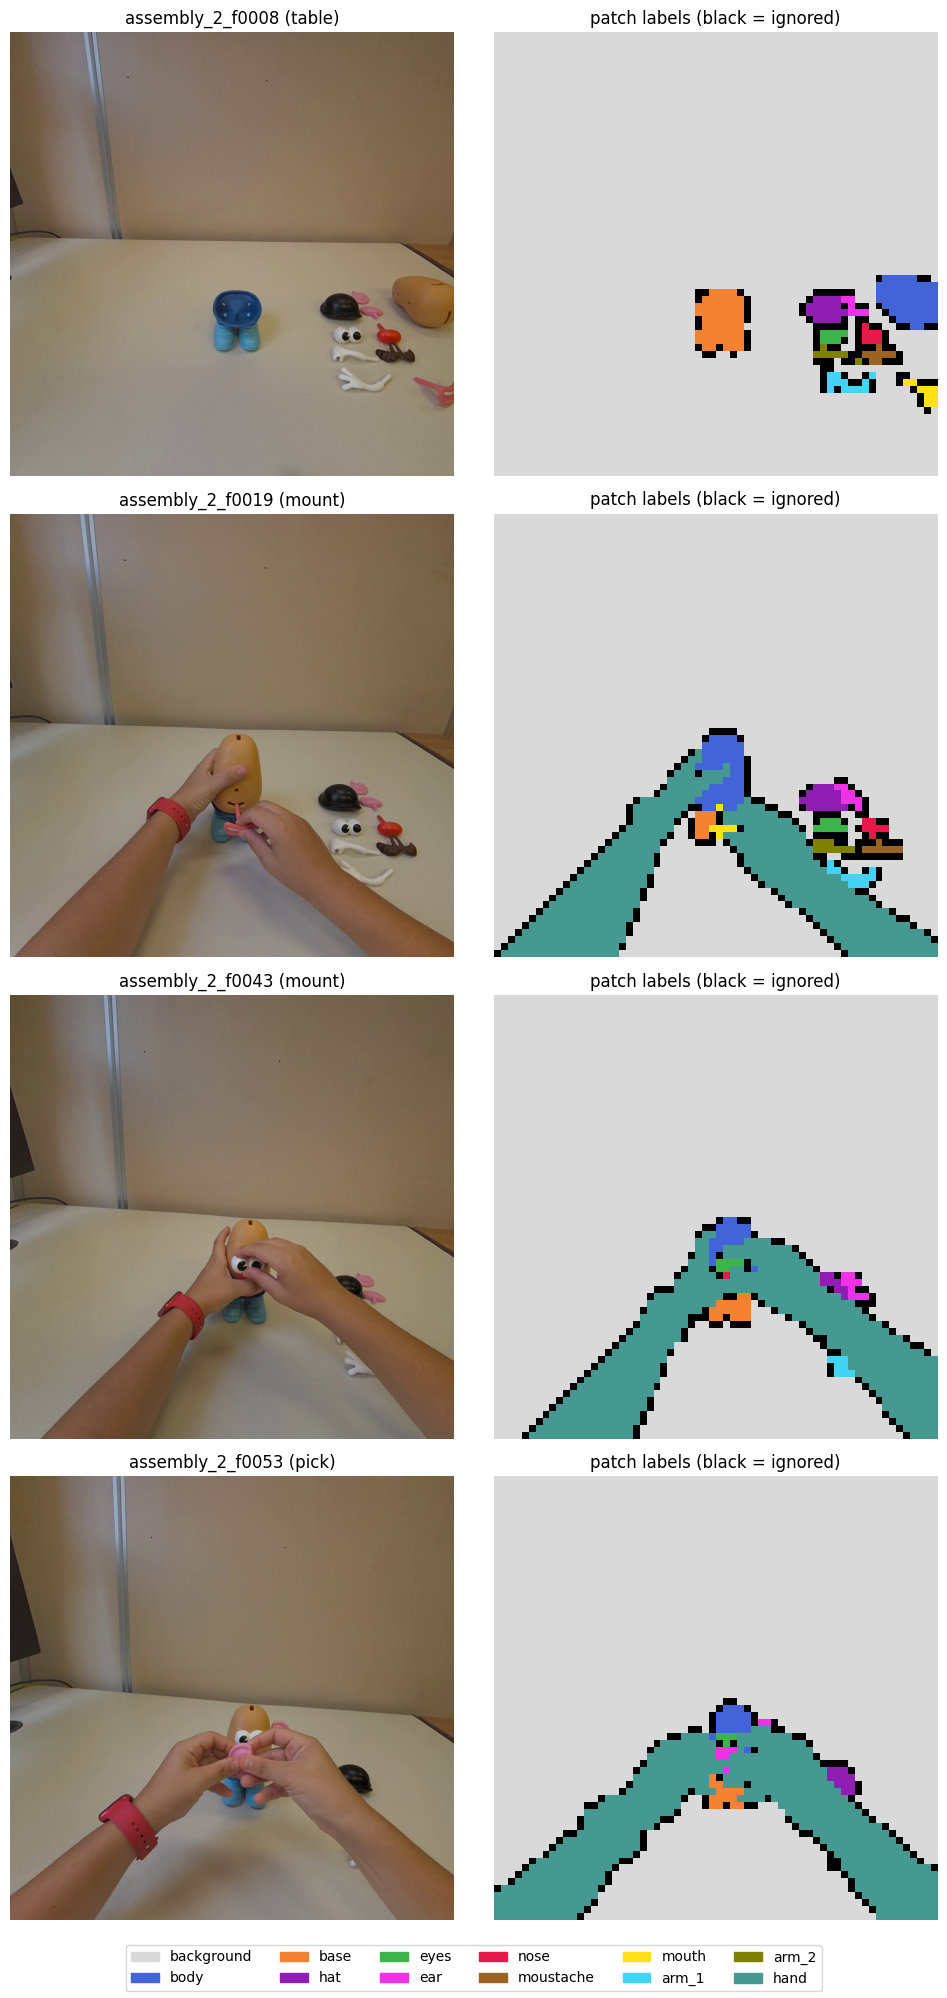

In [10]:
# 3.3 Ground truth of every validation frame (patch labels), and a visual check on four frames chosen before looking:
# the base alone (f0008), the mouth with its pin at the slot (f0019), the eyes mounted under a hand (f0043),
# an ear in hand against the head (f0053). In all four, polygons overlap: the smaller must win, and the hand must stay hand.
INPUT_SIZE = (1024, 1024)      # native size of the frames (resolution study); checked against the model in Section 4
PATCH_SIZE = 16                # patch size of C-RADIOv4; checked against the model in Section 4
for val in VALIDATION_FRAMES:
    pixel_map = rasterize_annotation(val["json_path"], GT_LABELS, INPUT_SIZE)
    val["gt"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

CHECK_FRAMES = ["assembly_2_f0008", "assembly_2_f0019", "assembly_2_f0043", "assembly_2_f0053"]
by_name = {val["frame"]: val for val in VALIDATION_FRAMES}
fig, axes = plt.subplots(len(CHECK_FRAMES), 2, figsize=(10, 5 * len(CHECK_FRAMES)))
present = set()
for row, name in zip(axes, CHECK_FRAMES):
    val = by_name[name]
    row[0].imshow(Image.open(val["image_path"]))
    row[0].set_title(f"{name} ({val['moment']})")
    row[1].imshow(label_grid_to_rgb(val["gt"]), interpolation="nearest")
    row[1].set_title("patch labels (black = ignored)")
    present |= {CLASS_NAMES[i] for i in np.unique(val["gt"]) if i != IGNORE_ID}
    for ax in row:
        ax.axis("off")
handles = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES if name in present]
fig.legend(handles=handles, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Observation 3.3: In the four frames the labels follow the rule of rasterize_annotation, the smaller polygon wins. In assembly_2_f0008 the base alone is labelled base over its whole area, its cavity included. In assembly_2_f0019 and assembly_2_f0043 the hands holding the body stay hand, and the pieces on the body, the mouth at its slot and the eyes, keep their own class over the body. In assembly_2_f0053 the ears and the visible part of the face stay separate from the hands that hold them.

The pieces being picked or mounted cover few patches. The mouth at its slot and the eyes entering their slot are a few patches each, mostly surrounded by hand. Borders between classes are ignored (black), as the labelling rule requires.

In [11]:
# 3.4 What the validation set contains: labelled patches of each class by moment, and the number of frames where it appears
records = []
for val in VALIDATION_FRAMES:
    ids, counts = np.unique(val["gt"], return_counts=True)
    records += [{"class": CLASS_NAMES[i], "moment": val["moment"], "patches": int(n)}
                for i, n in zip(ids, counts) if i not in (BACKGROUND_ID, IGNORE_ID)]
records = pd.DataFrame(records)
order = [name for name in CLASS_NAMES if name in set(records["class"])]
moments = ["table", "pick", "mount"]
patches = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="sum", fill_value=0)
frames = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="count", fill_value=0)
patches, frames = patches.reindex(index=order, columns=moments, fill_value=0), frames.reindex(index=order, columns=moments, fill_value=0)
patches["total"], frames["total"] = patches.sum(axis=1), frames.sum(axis=1)
print("Labelled patches:")
display(patches)
print("Frames where the class appears:")
display(frames)
ignored = sum(int((val["gt"] == IGNORE_ID).sum()) for val in VALIDATION_FRAMES)
print(f"Ignored patches (mixed borders): {ignored} of {len(VALIDATION_FRAMES) * 64 * 64}")

Labelled patches:


moment,table,pick,mount,total
class,,,,
body,404,446,447,1297
base,305,282,197,784
hat,188,193,154,535
eyes,83,90,76,249
ear,91,105,99,295
nose,69,57,59,185
moustache,75,82,58,215
mouth,49,51,29,129
arm_1,100,95,67,262


Frames where the class appears:


moment,table,pick,mount,total
class,,,,
body,10,11,11,32
base,10,11,11,32
hat,10,11,10,31
eyes,10,11,9,30
ear,10,11,11,32
nose,10,10,10,30
moustache,10,10,9,29
mouth,10,10,8,28
arm_1,10,10,11,31


Ignored patches (mixed borders): 3463 of 131072


Observation 3.4: Every piece appears in at least 28 of the 32 frames, and in at least 8 frames of each moment. Hand appears in 27 frames, and its patches grow from 830 at the table to 2942 at the pick and 5560 at the mounting. Hand is not part of the mIoU over the pieces.

The pieces have few labelled patches, and fewer at the mounting, where the hands cover them. Body has 1297 patches in all and base 784. Mouth has 129, of which 29 at the mounting over 8 frames. Nose has 185 and arm_2 167. The IoU of a single piece within a single moment therefore rests on a few dozen patches, while the mIoU of a moment pools ten pieces. Ignored border patches are 3463 of 131072, about 2.6%.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

extract_frames.py: one frame every 30 video frames, named by its position in the extracted sequence.

configs/assembly_2_events.json: touch, insert and hands_off of every piece, notes on touches without lifting and on the ear put back; field revision for the revision made for this study.

src/perception/labels.py, rasterize_annotation: polygons are drawn from the largest to the smallest, so a piece on top of another wins; patch_label_grid: the labelling rule of the pipeline (Section 5).

Support-set study, Section 4: the 6 old validation frames and their annotation.

Cawley and Talbot 2010, Sect. 5: a performance estimate on data used for selection is optimistically biased; the validation frames are therefore chosen by rules, not by results.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Regression check

Before changing the support set, this section checks that the current V2 is exactly the one of the margin study. Otherwise a difference found later could come from the code or from the computation, and not from the frames.

Four things are checked. The model must have the patch size and the input size assumed in Section 3.3. The current support set must give the same number of V2 prototypes as before. The labels computed on the GPU, which this study uses, must equal those computed on the CPU, which the margin study used for its measures. And on the 8 validation frames of the margin study, at background margin 0, the mIoU must equal the values reported there.

The two frames of 1_disassembled_controlled_caos are read here only for this check, as they were read by the previous studies. The ground truth of the 6 old assembly_2 frames is compared with the one built in Section 3.3, which must be identical.

In [12]:
# 4.1 Loading the model (shared FeatureExtractor, same settings as the pipeline), and the sizes assumed in Section 3.3
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
print(f"Model loaded, patch size {extractor.patch_size}x{extractor.patch_size}, "
      f"input size for a 1024x1024 frame: {extractor.input_size(*INPUT_SIZE)}")
assert extractor.patch_size == PATCH_SIZE
assert extractor.input_size(*INPUT_SIZE) == INPUT_SIZE

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16, input size for a 1024x1024 frame: (1024, 1024)


Observation 4.1: The model has patches of 16x16 pixels and keeps a 1024x1024 frame at 1024x1024, the sizes assumed in Section 3.3. The validation ground truth is therefore on the grid of the model, 64x64 patches.

In [13]:
# 4.2 Current support set: features, patch labels and the V2 prototypes (every labelled patch), as in the margin study (Section 3.2)
for ref in CURRENT_SUPPORT:
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], size = extractor.extract(image)
    assert size == INPUT_SIZE
    ref["patch_labels"], _ = patch_label_grid(rasterize_annotation(ref["json_path"], ref["use_labels"], size),
                                              PATCH_SIZE, MIN_LABEL_COVERAGE)


def v2_on_gpu(prototypes, owners):
    """V2 prototypes sorted by class and moved once to the GPU, as class_similarities_gpu requires."""
    prototypes, owners = sort_by_class(prototypes, owners)
    return torch.as_tensor(prototypes, device=DEVICE), torch.as_tensor(owners, device=DEVICE)


CURRENT_V2_CPU = patch_prototypes(CURRENT_SUPPORT)
CURRENT_V2 = v2_on_gpu(*CURRENT_V2_CPU)
counts = pd.Series(np.bincount(CURRENT_V2_CPU[1], minlength=len(CLASS_NAMES)), index=CLASS_NAMES)
display(counts.to_frame("prototypes").T)
print(f"V2 prototypes: {counts.sum()}, of which background {counts['background']}")
assert counts.sum() == 39125 and counts["background"] == 37864   # margin study, Observation 3.2

,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,37864,302,201,52,32,52,29,35,28,33,15,482


V2 prototypes: 39125, of which background 37864


Observation 4.2: The current support set gives 39,125 V2 prototypes, of which 37,864 are background, as in the margin study (Observation 3.2). The classes are very unequal. Hand has 482 prototypes and body 302, while arm_2 has 15, mouth 28, nose 29 and eyes 32. Each small piece rests on a few dozen labelled patches, so a single frame with a missing appearance of that piece can change what V2 recognizes (Section 1).

In [14]:
# 4.3 Regression check on the 8 validation frames of the margin study, at background margin 0:
# labels on the GPU equal labels on the CPU, the ground truth of the old frames equals Section 3.3,
# and the mIoU equals the values reported there (margin study, Observation 6.4; rounded to 3 decimals)
from perception.prototypes import class_similarities

by_name = {val["frame"]: val for val in VALIDATION_FRAMES}
OLD_VALIDATION = []
for item in MARGIN_STUDY_VALIDATION:
    image = Image.open(frame_path(item["frame"])).convert("RGB")
    features, size = extractor.extract(image)
    gt, _ = patch_label_grid(rasterize_annotation(frame_path(item["frame"], ".json"), GT_LABELS, size),
                             PATCH_SIZE, MIN_LABEL_COVERAGE)
    labels_gpu = assign_labels(class_similarities_gpu(features, *CURRENT_V2), MARGIN)
    labels_cpu = assign_labels(class_similarities(features, *CURRENT_V2_CPU), MARGIN)
    OLD_VALIDATION.append({"frame": item["frame"], "gt": gt, "gt_tolerant": ignore_boundary_ring(gt, BOUNDARY_RING),
                           "labels": labels_gpu,
                           "patches different GPU/CPU": int((labels_gpu != labels_cpu).sum()),
                           "ground truth as Section 3.3": (bool((gt == by_name[item["frame"]]["gt"]).all())
                                                           if item["frame"] in by_name else "not in the new set")})
OLD_EXCLUDED = [{CLASS_NAMES.index(name) for name in item.get("exclude", set())} for item in MARGIN_STUDY_VALIDATION]
display(pd.DataFrame(OLD_VALIDATION).set_index("frame")[["patches different GPU/CPU", "ground truth as Section 3.3"]])

REPORTED = {("gt", False): 0.823, ("gt", True): 0.864, ("gt_tolerant", False): 0.823, ("gt_tolerant", True): 0.865}
rows = []
for (gt_key, merge), reported in REPORTED.items():
    confusions = [confusion_matrix(val[gt_key], val["labels"]) for val in OLD_VALIDATION]
    obtained = round(frame_miou(confusions, OLD_EXCLUDED, merge=merge), 3)
    rows.append({"metric": "main" if gt_key == "gt" else "boundary ring ignored",
                 "classes": "arms merged" if merge else "10 pieces",
                 "mIoU": obtained, "reported": reported, "equal": obtained == reported})
regression = pd.DataFrame(rows)
display(regression)
assert regression["equal"].all()
assert sum(val["patches different GPU/CPU"] for val in OLD_VALIDATION) == 0
print("The current V2 reproduces the margin study.")

,patches different GPU/CPU,ground truth as Section 3.3
frame,,
assembly_2_f0003,0,True
assembly_2_f0017,0,True
assembly_2_f0030,0,True
assembly_2_f0046,0,True
assembly_2_f0057,0,True
assembly_2_f0068,0,True
1_disassembled_controlled_caos_f0001,0,not in the new set
1_disassembled_controlled_caos_f0016,0,not in the new set


,metric,classes,mIoU,reported,equal
0,main,10 pieces,0.823,0.823,True
1,main,arms merged,0.864,0.864,True
2,boundary ring ignored,10 pieces,0.823,0.823,True
3,boundary ring ignored,arms merged,0.865,0.865,True


The current V2 reproduces the margin study.


Observation 4.3: On the 8 validation frames of the margin study, the labels computed on the GPU equal those computed on the CPU on every patch. The ground truth of the 6 old assembly_2 frames equals the one built in Section 3.3. At background margin 0 the mIoU is 0.823 over the 10 pieces and 0.864 with the arms merged on the main metric, and 0.823 and 0.865 with the boundary ring ignored, the values of the margin study (Observation 6.4).

The current V2 therefore reproduces the margin study exactly. Any difference found in the next sections comes from the support set, not from the code or the computation.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4: none. The reference values are those of the margin study (Observation 3.2 and 6.4); the GPU computation is the one checked against the CPU in the multi-prototype study (Section 7.2).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - States and candidates

This section writes down which state of each piece every candidate shows, and computes from it which states are covered and by how many candidates. It uses no prediction.

A piece has two states (Section 1). Mounted means that the piece touches the part it is mounted on, as in the rule for the mount frames of the validation set (Section 3): the body is mounted when it stands on the base, the base when the body stands on it. Loose is every other case, on the table or in a hand. The state of every piece in every candidate is an annotated attribute, written by hand before any result, as the viewpoint in PASCAL VOC (Everingham et al. 2010, Sect. 3.3). A piece can have both states in the same frame, as the two ears when one is mounted and the other is not.

The attribute is checked against the annotation files: every piece with a state must be annotated and used in that frame, and every piece annotated and used must have a state (Section 5.1). The coverage table counts, for each piece and state, the candidates that show it (Section 5.2). A state shown by a single candidate makes that candidate impossible to remove (Section 1). Section 5.3 counts the labelled patches that every candidate adds to V2, that is the storage that removing it would save (García et al. 2012, Sect. 3.1.5).

In [15]:
# 5.1 State of every piece in every candidate (annotated attribute), checked against the annotation files
M, L = "mounted", "loose"
_LOOSE_NO_BASE = {piece: {L} for piece in PIECE_LABELS - {"base"}}      # disassembled frames: base split, not used
STATES = {
    "5_assembled_f0002":  {piece: {M} for piece in PIECE_LABELS},
    "5_assembled_f0019":  {piece: {M} for piece in PIECE_LABELS},
    "caos_f0278":         {piece: {M} for piece in PIECE_LABELS},
    "caos_f0149":         {"hat": {M}, "eyes": {M}, "mouth": {M}, "ear": {M, L},          # pieces on the lying body
                           "body": {L}, "base": {L}, "nose": {L}, "moustache": {L}, "arm_1": {L}},
    "caos_f0211":         {"ear": {M}, "nose": {M}, "moustache": {M},                    # nose and moustache touching the body
                           "body": {L}, "base": {L}, "hat": {L}, "eyes": {L}, "arm_1": {L}, "arm_2": {L}},
    "caos_f0043":         {"body": {M}, "base": {M}, "eyes": {M}, "ear": {M, L},
                           "hat": {L}, "nose": {L}, "moustache": {L}, "mouth": {L}, "arm_1": {L}, "arm_2": {L}},
    "4_partially_assembled_f0002": {"body": {M}, "base": {M}, "eyes": {M}, "ear": {M, L}, "arm_1": {M},
                                    "mouth": {L}, "nose": {L}, "moustache": {L}, "hat": {L}, "arm_2": {L}},
    "3_disassembled_ordered_f0001":         _LOOSE_NO_BASE,
    "2_disassembled_caos_f0016":            _LOOSE_NO_BASE,
    "1_disassembled_controlled_caos_f0001": _LOOSE_NO_BASE,
    "1_disassembled_controlled_caos_f0016": _LOOSE_NO_BASE,
    "Take_3_1_Base_f0099": {"base": {L}},
    "Take_3_1_Base_f0131": {"base": {L}},
}
assert set(STATES) == {item["frame"] for item in CANDIDATES}

rows = []
for item in CANDIDATES:
    annotated = check_annotation(item["image_path"], item["json_path"])
    used = annotated & item["use_labels"]
    item["annotated"], item["hands"] = annotated, HAND_LABEL in used
    with_state = set(STATES[item["frame"]])
    rows.append({"frame": item["frame"],
                 "pieces used": len(used & PIECE_LABELS),
                 "hands": item["hands"],
                 "used without a state": ", ".join(sorted((used & PIECE_LABELS) - with_state)) or "-",
                 "state without annotation": ", ".join(sorted(with_state - used)) or "-",
                 "annotated but not used": ", ".join(sorted(annotated - item["use_labels"])) or "-"})
state_check = pd.DataFrame(rows).set_index("frame")
display(state_check)
consistent = (state_check["used without a state"] == "-") & (state_check["state without annotation"] == "-")
print(f"Candidates whose states match their annotation: {consistent.sum()} of {len(state_check)}")

,pieces used,hands,used without a state,state without annotation,annotated but not used
frame,,,,,
5_assembled_f0002,10,False,-,-,-
5_assembled_f0019,10,False,-,-,-
caos_f0149,9,False,-,-,-
caos_f0211,9,True,-,-,-
caos_f0043,10,True,-,-,-
caos_f0278,10,True,-,-,-
3_disassembled_ordered_f0001,9,False,-,-,"pants, shoe"
2_disassembled_caos_f0016,9,False,-,-,"pants, shoe"
1_disassembled_controlled_caos_f0001,9,False,-,-,"pants, shoe"


Candidates whose states match their annotation: 13 of 13


Observation 5.1: The states written for the 13 candidates match their annotation files: every piece with a state is annotated and used, and every piece annotated and used has a state. The only labels annotated but not used are pants and shoe, the legacy labels of the split base in the four disassembled frames. All 10 pieces are annotated in 4_partially_assembled_f0002, where the current support set used only body and mouth; the other pieces were ignored there, not taken as background. Hands are used in three candidates: caos_f0211, caos_f0043 and caos_f0278.

In [16]:
# 5.2 Coverage: for each piece and state, the candidates that show it
coverage = {(piece, state): [frame for frame, states in STATES.items() if state in states.get(piece, set())]
            for piece in [name for name in CLASS_NAMES if name in PIECE_LABELS] for state in (L, M)}
coverage_table = pd.DataFrame([{"piece": piece, "state": state, "candidates": len(frames), "frames": ", ".join(frames)}
                               for (piece, state), frames in coverage.items()])
display(coverage_table.pivot(index="piece", columns="state", values="candidates")
        .reindex([name for name in CLASS_NAMES if name in PIECE_LABELS]))
uncovered = coverage_table[coverage_table["candidates"] == 0]
single = coverage_table[coverage_table["candidates"] == 1]
print(f"States not covered: {len(uncovered)}")
print(f"States covered by a single candidate: {len(single)}")
display(single[["piece", "state", "frames"]])
print(f"Candidates with hands: {[item['frame'] for item in CANDIDATES if item['hands']]}")

state,loose,mounted
piece,,
body,6,5
base,4,5
hat,7,4
eyes,5,6
ear,7,7
nose,7,4
moustache,7,4
mouth,6,4
arm_1,7,4


States not covered: 0
States covered by a single candidate: 0


,piece,state,frames


Candidates with hands: ['caos_f0211', 'caos_f0043', 'caos_f0278']


Observation 5.2: Every piece is covered in both states, and no state is covered by a single candidate. The loose states are covered by 4 to 7 candidates, the mounted states by 3 to 7. The thinnest is the mounted arm_2, shown only by the two frames of 5_assembled and by caos_f0278. At the start, therefore, the coverage constraint forbids no removal; it becomes active as candidates are removed (Section 6).

In [17]:
# 5.3 What each candidate adds to V2: its labelled patches, one prototype each (Section 4.2)
rows = []
for item in CANDIDATES:
    labels, _ = patch_label_grid(rasterize_annotation(item["json_path"], item["use_labels"], INPUT_SIZE),
                                 PATCH_SIZE, MIN_LABEL_COVERAGE)
    item["patch_labels"] = labels
    counts = np.bincount(labels.ravel(), minlength=IGNORE_ID + 1)
    rows.append({"frame": item["frame"], "background": int(counts[BACKGROUND_ID]),
                 "pieces": int(sum(counts[CLASS_NAMES.index(p)] for p in PIECE_LABELS)),
                 "hand": int(counts[CLASS_NAMES.index(HAND_LABEL)]), "ignored": int(counts[IGNORE_ID])})
cost = pd.DataFrame(rows).set_index("frame")
cost["prototypes"] = cost[["background", "pieces", "hand"]].sum(axis=1)
display(cost)
print(f"All candidates together: {cost['prototypes'].sum()} prototypes, "
      f"of which background {cost['background'].sum()} ({cost['background'].sum() / cost['prototypes'].sum():.0%})")

,background,pieces,hand,ignored,prototypes
frame,,,,,
5_assembled_f0002,3962,93,0,41,4055
5_assembled_f0019,3954,104,0,38,4058
caos_f0149,3850,168,0,78,4018
caos_f0211,3286,192,503,115,3981
caos_f0043,3303,164,475,154,3942
caos_f0278,3437,162,375,122,3974
3_disassembled_ordered_f0001,3733,159,0,204,3892
2_disassembled_caos_f0016,3858,95,0,143,3953
1_disassembled_controlled_caos_f0001,3879,107,0,110,3986


All candidates together: 52012 prototypes, of which background 49061 (94%)


Observation 5.3: Each candidate adds between 3892 and 4083 prototypes to V2, almost all of background, between 3286 and 4036. Pieces bring between 47 patches (Take_3_1_Base_f0099, the base alone) and 192 (caos_f0211), and hands between 375 and 503 in the three frames that show them. The 13 candidates together give 52,012 prototypes, 49,061 of them background, about 94%.

Removing any candidate therefore saves about the same storage, close to 4000 prototypes. The cost does not tell the candidates apart: which one to remove is decided by what its absence costs in recognition (Section 6). Since background dominates, a smaller background set would cut the storage further; this is outside this study, which removes whole frames.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Everingham et al. 2010, Sect. 3.3: the viewpoint of each object is annotated by hand as an attribute.

García et al. 2012, Sect. 3.1.5: storage reduction is one of the criteria for comparing prototype selection methods, together with generalization accuracy.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Choice of the support set

Rule of selection, fixed before this section was run.

The candidates are evaluated by leave-one-sequence-out cross-validation, as in the margin study (Section 4.1): each candidate is classified by the prototypes of the candidates of the other sequences in the subset, classes not used in that frame and hand are ignored, and the mIoU is computed with the arms merged on the main metric. All 13 candidates are always evaluated, also those removed from the subset, as Gates reclassifies the whole training set (Gates 1972, p. 432).

The search is decremental. Starting from the 13 candidates, at each step every remaining candidate whose removal leaves every state covered (Section 5) is removed in turn, and the one whose absence gives the highest cross-validated mIoU is removed. The search stops when no candidate can be removed without leaving a state uncovered. It gives a path of subsets of decreasing size.

The chosen subset is the smallest one on the path whose mIoU is no more than one standard error below the best mIoU on the path: the one-standard-error rule (Hastie et al. 2009, Sect. 7.10.1, p. 244). The rule recognizes that the cross-validated mIoU is estimated with error, and takes the simpler subset when the difference is within that error (Hastie et al. 2009, Sect. 3.3.4). The standard error is the standard deviation of the mIoU of the best subset over 1000 bootstrap resamples of the 13 candidates. Hastie et al. compute it from the folds; here the folds are 7 recordings of very different content, so the frames are resampled instead, as in the previous studies. Frames of one recording are correlated, so this standard error is likely too small (Künsch 1989, Sect. 1): the rule then keeps more frames, never fewer.

For comparison only, the subset where a strict rule would stop, removing a candidate only if the mIoU does not decrease, is also reported. It plays no part in the choice.

First run. The rule above was run at the level of frames, with the arms merged (commit "Section 6, decremental selection, 5 frames chosen"). It chose 5 frames: 5_assembled_f0019, caos_f0149, caos_f0211, Take_3_1_Base_f0131 and 4_partially_assembled_f0002, with a cross-validated mIoU of 0.821 with the arms merged and 20,149 prototypes. Along its path the mIoU over 10 pieces fell further than the mIoU with the arms merged: the gap grew from 0.021 with 13 candidates to 0.068 with 5, and the first large drop, from 0.819 to 0.795, came when caos_f0278 was removed. The smaller support sets confused arm_1 and arm_2.

Revision of the rule, fixed before the revised search was run. The validation set has not been used. Two things change, for reasons of the task rather than of the result.

The metric is the mIoU over the 10 pieces. arm_1 and arm_2 are distinct pieces, each mounted on its own side, and mounting one in the place of the other is an error that Phase 2 must detect. A metric that merges them cannot see that error.

The unit removed is an object, not a frame: every piece in every candidate, the background of every candidate, and the hands of every candidate that shows them. A frame was chosen as the unit because annotating a frame was the cost; all 13 candidates are now annotated, so the remaining cost is storage, the prototypes, and the natural unit is the example, as in Hart, Gates and García et al. A piece unit covers the states that piece shows in its frame (Section 5).

Everything else stays as above: leave-one-sequence-out cross-validation on all 13 candidates, decremental search removing at each step the unit whose absence gives the highest mIoU, ties broken by the order of the units, and the one-standard-error rule on the path, with the standard error from 1000 bootstrap resamples of the candidates. The constraint becomes: every state of every piece stays covered, at least one hands unit stays, and every candidate keeps a background unit from another recording, so that the cross-validation can classify it. Among the subsets within one standard error of the best, the chosen one is the last on the path, which has the fewest units and prototypes. The strict rule is again reported for comparison only.

In [21]:
# 6.1 Cross-validation material: features of the candidates, ground truth with hand ignored (margin study, Section 4.1),
# and the class similarities of every candidate with the prototypes of every candidate of another sequence.
# In V2 the similarity with a class is the maximum over its prototypes, so the similarity with a subset of frames is the
# element-wise maximum of the similarities with each frame: every subset is then evaluated without recomputing.
HAND_ID = CLASS_NAMES.index(HAND_LABEL)
NO_EXCLUSION = [set() for _ in CANDIDATES]      # as in the margin study: no class excluded in the cross-validation
SEQUENCES = [sequence_of(item["frame"]) for item in CANDIDATES]

for item in CANDIDATES:
    image = Image.open(item["image_path"]).convert("RGB")
    item["features"], size = extractor.extract(image)
    assert size == INPUT_SIZE
    item["cv_gt"] = np.where(item["patch_labels"] == HAND_ID, IGNORE_ID, item["patch_labels"])


def similarity_to_frame(features, prototypes, owners):
    """Similarity of each patch with each class, from the prototypes of one frame (GPU, float32).
    Classes without prototypes in that frame get -inf, so a subset without them can never predict them."""
    x = torch.as_tensor(l2_normalize(features), device=DEVICE).reshape(-1, features.shape[-1])
    similarities = x @ prototypes.T
    out = torch.full((x.shape[0], len(CLASS_NAMES)), -torch.inf, device=DEVICE)
    for class_id in torch.unique(owners).tolist():
        out[:, class_id] = similarities[:, owners == class_id].amax(dim=1)
    return out.reshape(*features.shape[:-1], len(CLASS_NAMES)).cpu().numpy()


SIM = {}                                     # SIM[i, j]: candidate i classified by the prototypes of candidate j only
for j, item in enumerate(CANDIDATES):
    prototypes, owners = patch_prototypes([item])
    prototypes = torch.as_tensor(prototypes, device=DEVICE)
    owners = torch.as_tensor(owners, device=DEVICE)
    for i, other in enumerate(CANDIDATES):
        if SEQUENCES[i] != SEQUENCES[j]:
            SIM[i, j] = similarity_to_frame(other["features"], prototypes, owners)
print(f"{len(CANDIDATES)} candidates from {len(set(SEQUENCES))} sequences, {len(SIM)} similarity maps")

# Exactness check: the maximum over the frames equals V2 built from the same frames, computed on the CPU
i = 0                                        # 5_assembled_f0002, classified by all candidates of the other sequences
others = [j for j in range(len(CANDIDATES)) if SEQUENCES[j] != SEQUENCES[i]]
from_maps = np.max(np.stack([SIM[i, j] for j in others]), axis=0)
direct = class_similarities(CANDIDATES[i]["features"], *patch_prototypes([CANDIDATES[j] for j in others]))
print(f"Largest difference with V2 on the CPU: {np.abs(from_maps - direct).max():.2e}; "
      f"patches with a different label: {int((assign_labels(from_maps, MARGIN) != assign_labels(direct, MARGIN)).sum())}")
assert (assign_labels(from_maps, MARGIN) == assign_labels(direct, MARGIN)).all()

13 candidates from 7 sequences, 138 similarity maps
Largest difference with V2 on the CPU: 1.79e-06; patches with a different label: 0


In [22]:
# 6.2 Units of selection (revision): every piece in every candidate, the background of every candidate, the hands of every
# candidate that shows them. Similarity of every candidate with every unit of another sequence (GPU, float32).
UNITS = []
for j, item in enumerate(CANDIDATES):
    for class_id, name in enumerate(CLASS_NAMES):
        n = int((item["patch_labels"] == class_id).sum())
        if n:
            UNITS.append({"candidate": j, "frame": item["frame"], "class": name, "class_id": class_id, "prototypes": n,
                          "states": {(name, s) for s in STATES[item["frame"]].get(name, set())}})
UNIT_CLASS = np.array([u["class_id"] for u in UNITS])
UNIT_SEQUENCE = np.array([SEQUENCES[u["candidate"]] for u in UNITS])
UNIT_COST = np.array([u["prototypes"] for u in UNITS])
print(f"{len(UNITS)} units: {(UNIT_CLASS == BACKGROUND_ID).sum()} background, {(UNIT_CLASS == HAND_ID).sum()} hands, "
      f"{np.isin(UNIT_CLASS, [CLASS_NAMES.index(p) for p in PIECE_LABELS]).sum()} pieces; {UNIT_COST.sum()} prototypes")

n_patches = (INPUT_SIZE[0] // PATCH_SIZE) * (INPUT_SIZE[1] // PATCH_SIZE)
patches_gpu = [torch.as_tensor(l2_normalize(item["features"]).reshape(-1, item["features"].shape[-1]), device=DEVICE)
               for item in CANDIDATES]
UNIT_SIM = np.full((len(CANDIDATES), len(UNITS), n_patches), -np.inf, dtype=np.float32)
for u, unit in enumerate(UNITS):
    item = CANDIDATES[unit["candidate"]]
    prototypes = torch.as_tensor(l2_normalize(item["features"])[item["patch_labels"] == unit["class_id"]], device=DEVICE)
    for i in range(len(CANDIDATES)):
        if SEQUENCES[i] != UNIT_SEQUENCE[u]:
            UNIT_SIM[i, u] = (patches_gpu[i] @ prototypes.T).amax(dim=1).cpu().numpy()


def unit_similarities(i, mask):
    """Class similarities of candidate i with the units in mask: per class, the maximum over its units (-inf if none)."""
    out = np.full((n_patches, len(CLASS_NAMES)), -np.inf, dtype=np.float32)
    for class_id in range(len(CLASS_NAMES)):
        rows = mask & (UNIT_CLASS == class_id)
        if rows.any():
            out[:, class_id] = UNIT_SIM[i, rows].max(axis=0)
    return out.reshape(*CANDIDATES[i]["features"].shape[:-1], len(CLASS_NAMES))


# Exactness check: with every unit, the units give the same similarities as the frames (Section 6.1)
everything = np.ones(len(UNITS), dtype=bool)
i = 0
print(f"Largest difference with the frame maps: {np.abs(unit_similarities(i, everything) - from_maps).max():.2e}")
assert (assign_labels(unit_similarities(i, everything), MARGIN) == assign_labels(from_maps, MARGIN)).all()

122 units: 13 background, 3 hands, 106 pieces; 52012 prototypes
Largest difference with the frame maps: 1.97e-06


Observation 6.2: The 13 candidates give 122 units: 106 pieces, 13 backgrounds and 3 hands, 52,012 prototypes in all. With every unit, the class similarities equal those computed from the frames (largest difference 2.0e-6, no label changed), so the search on the units is exact for V2.

In [23]:
# 6.3 Decremental search on the units (revised rule): at each step remove the unit whose absence gives the highest
# cross-validated mIoU over the 10 pieces, among the removals that keep the constraint. Ties: order of the units.
def unit_confusions(mask):
    return [confusion_matrix(item["cv_gt"], assign_labels(unit_similarities(i, mask), MARGIN))
            for i, item in enumerate(CANDIDATES)]


def unit_miou(mask, merge=False):
    return frame_miou(unit_confusions(mask), NO_EXCLUSION, merge=merge)


def keeps_constraint(mask):
    covered = set().union(*[UNITS[u]["states"] for u in np.flatnonzero(mask)])
    if not set(coverage) <= covered:
        return False                                                     # every state of every piece
    if not (mask & (UNIT_CLASS == HAND_ID)).any():
        return False                                                     # at least one hands unit
    background = mask & (UNIT_CLASS == BACKGROUND_ID)
    return all((background & (UNIT_SEQUENCE != s)).any() for s in SEQUENCES)   # background from another recording


mask = np.ones(len(UNITS), dtype=bool)
assert keeps_constraint(mask)
unit_path = [{"removed": "-", "mask": mask.copy()}]
while True:
    options = []
    for position, u in enumerate(np.flatnonzero(mask)):
        trial = mask.copy()
        trial[u] = False
        if keeps_constraint(trial):
            options.append((unit_miou(trial), -position, u))
    if not options:
        break
    _, _, removed = max(options)
    mask[removed] = False
    unit_path.append({"removed": f"{UNITS[removed]['frame']}: {UNITS[removed]['class']}", "mask": mask.copy()})
    if len(unit_path) % 20 == 0:
        print(f"step {len(unit_path) - 1}, {mask.sum()} units left")

for step in unit_path:
    step["units"] = int(step["mask"].sum())
    step["prototypes"] = int(UNIT_COST[step["mask"]].sum())
    step["frames"] = len({UNITS[u]["candidate"] for u in np.flatnonzero(step["mask"])})
    step["mIoU (10 pieces)"] = unit_miou(step["mask"])
    step["mIoU (arms merged)"] = unit_miou(step["mask"], merge=True)
unit_path_table = pd.DataFrame(unit_path)[["removed", "units", "frames", "prototypes", "mIoU (10 pieces)", "mIoU (arms merged)"]]
pd.set_option("display.max_rows", 200)
display(unit_path_table.round(3))

step 19, 103 units left
step 39, 83 units left
step 59, 63 units left
step 79, 43 units left
step 99, 23 units left


,removed,units,frames,prototypes,mIoU (10 pieces),mIoU (arms merged)
0,-,122,13,52012,0.803,0.824
1,2_disassembled_caos_f0016: hat,121,13,52003,0.811,0.832
2,1_disassembled_controlled_caos_f0016: ear,120,13,51997,0.818,0.840
3,2_disassembled_caos_f0016: arm_1,119,13,51994,0.825,0.840
4,1_disassembled_controlled_caos_f0001: ear,118,13,51987,0.830,0.846
5,2_disassembled_caos_f0016: mouth,117,13,51983,0.835,0.851
6,caos_f0043: mouth,116,13,51982,0.840,0.857
7,5_assembled_f0002: eyes,115,13,51974,0.844,0.861
8,Take_3_1_Base_f0099: base,114,13,51927,0.847,0.864
9,3_disassembled_ordered_f0001: ear,113,13,51917,0.849,0.867


Observation 6.3: Removing units first raises the cross-validated mIoU over the 10 pieces, from 0.803 with every unit to 0.867 at step 24, with 98 units and 51,555 prototypes. Most of the first units removed are loose pieces of the disassembled frames: the hat, an arm and the mouth of 2_disassembled_caos_f0016, the ears of both 1_disassembled_controlled_caos frames. The mIoU then stays nearly flat for many steps, and falls at the end of the path, where the constraint stops it with 22 units from 9 frames.

As in the first run, a rise when examples are removed matches the effect of edition in prototype selection (García et al. 2012, Sect. 3.1.2); here it is larger because single pieces, not whole frames, can be removed.

All units: mIoU 0.803 (10 pieces), 52012 prototypes
Best on the path: mIoU 0.867 at step 24; standard error 0.018; threshold 0.849
Chosen (one-standard-error rule): step 78, 44 units from 12 frames, 20346 prototypes, mIoU 0.851 (arms merged 0.871)
Strict rule, for comparison only: step 65, 57 units, 31798 prototypes
Subsets compared along the path: 6971


class,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
frame,,,,,,,,,,,,
1_disassembled_controlled_caos_f0001,3879,0,0,0,0,0,1,0,0,3,0,0
1_disassembled_controlled_caos_f0016,3883,60,0,0,3,0,0,0,4,0,1,0
2_disassembled_caos_f0016,3858,0,0,0,0,0,0,0,0,0,3,0
3_disassembled_ordered_f0001,0,0,0,10,0,0,0,5,0,4,4,0
4_partially_assembled_f0002,3863,0,0,0,0,15,3,10,3,7,0,0
5_assembled_f0002,3962,0,0,11,0,0,0,0,0,5,0,0
5_assembled_f0019,0,25,17,0,8,0,6,8,4,0,4,0
Take_3_1_Base_f0131,0,0,58,0,0,0,0,0,0,0,0,0
caos_f0043,0,62,0,0,0,18,0,0,0,0,8,0


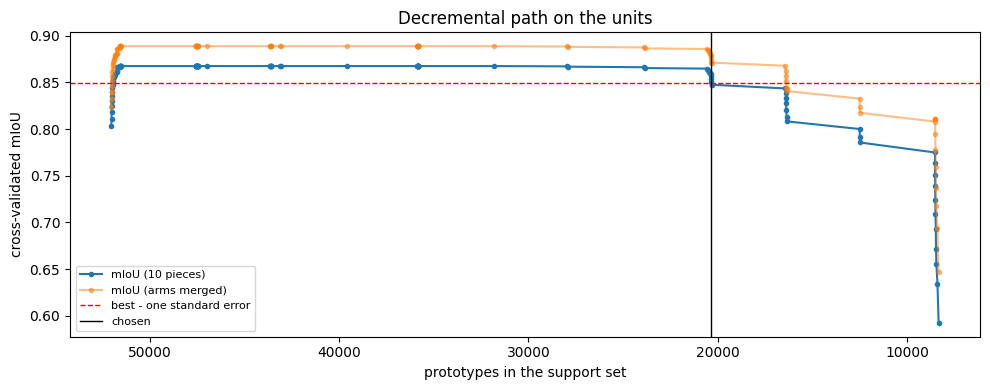

In [25]:
# 6.4 One-standard-error rule on the units (Hastie et al. 2009, Sect. 7.10.1), 10-piece mIoU
best = int(np.argmax(unit_path_table["mIoU (10 pieces)"]))
rng = np.random.default_rng(RANDOM_SEED)
resamples = rng.integers(0, len(CANDIDATES), size=(N_BOOTSTRAP, len(CANDIDATES)))
best_bootstrap = bootstrap_miou(unit_confusions(unit_path[best]["mask"]), NO_EXCLUSION, resamples, merge=False)
standard_error = float(np.nanstd(best_bootstrap, ddof=1))
threshold = unit_path_table.loc[best, "mIoU (10 pieces)"] - standard_error
chosen = int(unit_path_table.index[unit_path_table["mIoU (10 pieces)"] >= threshold].max())
drops = np.where(np.diff(unit_path_table["mIoU (10 pieces)"].to_numpy()) < 0)[0]
strict = int(drops[0]) if len(drops) else len(unit_path_table) - 1

row = unit_path_table.loc
print(f"All units: mIoU {row[0, 'mIoU (10 pieces)']:.3f} (10 pieces), {row[0, 'prototypes']} prototypes")
print(f"Best on the path: mIoU {row[best, 'mIoU (10 pieces)']:.3f} at step {best}; standard error {standard_error:.3f}; "
      f"threshold {threshold:.3f}")
print(f"Chosen (one-standard-error rule): step {chosen}, {row[chosen, 'units']} units from {row[chosen, 'frames']} frames, "
      f"{row[chosen, 'prototypes']} prototypes, mIoU {row[chosen, 'mIoU (10 pieces)']:.3f} "
      f"(arms merged {row[chosen, 'mIoU (arms merged)']:.3f})")
print(f"Strict rule, for comparison only: step {strict}, {row[strict, 'units']} units, {row[strict, 'prototypes']} prototypes")
compared = sum(sum(keeps_constraint(step["mask"] & (np.arange(len(UNITS)) != u)) for u in np.flatnonzero(step["mask"]))
               for step in unit_path[:-1])
print(f"Subsets compared along the path: {compared}")

CHOSEN_MASK = unit_path[chosen]["mask"]
kept = pd.DataFrame([UNITS[u] for u in np.flatnonzero(CHOSEN_MASK)])
display(kept.pivot_table(index="frame", columns="class", values="prototypes", aggfunc="sum", fill_value=0)
        .reindex(columns=[n for n in CLASS_NAMES if n in set(kept["class"])]))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(unit_path_table["prototypes"], unit_path_table["mIoU (10 pieces)"], marker=".", label="mIoU (10 pieces)")
ax.plot(unit_path_table["prototypes"], unit_path_table["mIoU (arms merged)"], marker=".", alpha=0.5, label="mIoU (arms merged)")
ax.axhline(threshold, color="red", linestyle="--", linewidth=1, label="best - one standard error")
ax.axvline(row[chosen, "prototypes"], color="black", linewidth=1, label="chosen")
ax.invert_xaxis()
ax.set(xlabel="prototypes in the support set", ylabel="cross-validated mIoU", title="Decremental path on the units")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Observation 6.4: The best mIoU on the path is 0.867 (step 24); its standard error is 0.018, so the threshold is 0.849. The one-standard-error rule chooses step 78: 44 units from 12 frames, 20,346 prototypes, a cross-validated mIoU of 0.851 over 10 pieces and 0.871 with the arms merged. The strict rule, reported for comparison only, would stop at step 65 with 57 units and 31,798 prototypes.

The background is kept from 5 frames: both frames of 1_disassembled_controlled_caos, 2_disassembled_caos_f0016, 4_partially_assembled_f0002 and 5_assembled_f0002. The pieces keep between 1 and 62 patches per unit. Hands are kept only from caos_f0278, with bare hands. caos_f0278, the figure mounted at working distance, keeps its body, base, eyes, nose and arm_2.

With almost the same storage as the first run (20,149 prototypes), the selection by objects gives a mIoU over 10 pieces of 0.851 against 0.753, and 0.871 against 0.821 with the arms merged.

These cross-validated values are optimistic. The path compared 6,971 subsets on the same 13 frames, and a criterion optimized over many choices on a small sample over-fits it (Cawley and Talbot 2010, Sect. 4.4). The rise along the path is partly real, the removal of misleading examples, and partly an adaptation to these 13 frames. The performance of the chosen set is measured on the validation set, never used so far (Section 8).

In [26]:
# 6.5 What the selection kept (description, no choice): hands in every candidate, and the size of every piece unit in
# patches, compared with the size of the same piece in the validation frames (the scale of use). The viewpoint is not
# recorded: in egocentric video it has no fixed reference, so a label such as "frontal" is a perception, not a measure.
HANDS = {"5_assembled_f0002": "none", "5_assembled_f0019": "none", "caos_f0149": "none",
         "caos_f0211": "bare and glove", "caos_f0043": "glove", "caos_f0278": "bare",
         "3_disassembled_ordered_f0001": "none", "2_disassembled_caos_f0016": "none",
         "1_disassembled_controlled_caos_f0001": "none", "1_disassembled_controlled_caos_f0016": "none",
         "Take_3_1_Base_f0099": "none", "Take_3_1_Base_f0131": "none", "4_partially_assembled_f0002": "none"}
assert set(HANDS) == {item["frame"] for item in CANDIDATES}

rows = []
for j, item in enumerate(CANDIDATES):
    in_frame = [u for u in range(len(UNITS)) if UNITS[u]["candidate"] == j]
    kept = [u for u in in_frame if CHOSEN_MASK[u]]
    rows.append({"frame": item["frame"], "hands": HANDS[item["frame"]],
                 "units kept": f"{len(kept)} of {len(in_frame)}",
                 "background kept": any(UNIT_CLASS[u] == BACKGROUND_ID for u in kept),
                 "prototypes kept": int(UNIT_COST[kept].sum()), "prototypes": int(UNIT_COST[in_frame].sum())})
display(pd.DataFrame(rows).set_index("frame"))

# Size of each piece: patches per unit in the candidates (kept or removed), and per frame in the validation set
validation_size = {piece: np.median([int((val["gt"] == CLASS_NAMES.index(piece)).sum()) for val in VALIDATION_FRAMES
                                     if (val["gt"] == CLASS_NAMES.index(piece)).any()])
                   for piece in PIECE_LABELS}
rows = []
for piece in [name for name in CLASS_NAMES if name in PIECE_LABELS]:
    units = [u for u in range(len(UNITS)) if UNITS[u]["class"] == piece]
    kept = [UNIT_COST[u] for u in units if CHOSEN_MASK[u]]
    removed = [UNIT_COST[u] for u in units if not CHOSEN_MASK[u]]
    rows.append({"piece": piece, "validation (median patches)": validation_size[piece],
                 "kept: patches per unit": sorted(int(n) for n in kept),
                 "removed: patches per unit": sorted(int(n) for n in removed)})
display(pd.DataFrame(rows).set_index("piece"))

,hands,units kept,background kept,prototypes kept,prototypes
frame,,,,,
5_assembled_f0002,none,3 of 11,True,3978,4055
5_assembled_f0019,none,7 of 11,False,72,4058
caos_f0149,none,1 of 10,False,6,4018
caos_f0211,bare and glove,3 of 11,False,56,3981
caos_f0043,glove,3 of 12,False,88,3942
caos_f0278,bare,6 of 12,False,469,3974
3_disassembled_ordered_f0001,none,4 of 10,False,23,3892
2_disassembled_caos_f0016,none,2 of 10,True,3861,3953
1_disassembled_controlled_caos_f0001,none,3 of 10,True,3883,3986


,validation (median patches),kept: patches per unit,removed: patches per unit
piece,,,
body,36.0,"[25, 36, 60, 62]","[20, 40, 51, 57, 67, 81, 109]"
base,23.0,"[17, 30, 36, 58]","[18, 20, 23, 47, 59]"
hat,18.0,"[10, 11]","[8, 9, 11, 13, 14, 16, 28, 28, 29]"
eyes,8.0,"[2, 3, 8, 12]","[4, 4, 6, 6, 8, 8, 13]"
ear,8.0,"[15, 18]","[6, 7, 7, 10, 11, 11, 13, 18, 18]"
nose,7.0,"[1, 3, 6, 10]","[2, 3, 5, 5, 6, 10, 17]"
moustache,7.0,"[5, 8, 10, 18]","[5, 5, 5, 5, 6, 9, 12]"
mouth,3.5,"[3, 4, 4, 6]","[1, 3, 4, 4, 5, 6]"
arm_1,10.0,"[3, 4, 5, 7]","[1, 2, 3, 5, 5, 10, 16]"


In [27]:
# 6.6 How many whole frames (description, no choice): the decremental path on whole frames, with the 10-piece mIoU.
# It answers how many frames to record and annotate; the support set itself is the one chosen by objects (Section 6.4).
def frame_confusions(subset):
    confusions = []
    for i, item in enumerate(CANDIDATES):
        maps = [SIM[i, j] for j in subset if SEQUENCES[j] != SEQUENCES[i]]
        confusions.append(confusion_matrix(item["cv_gt"], assign_labels(np.max(np.stack(maps), axis=0), MARGIN)))
    return confusions


def frame_covers(subset):
    return all(any(state in STATES[CANDIDATES[j]["frame"]].get(piece, set()) for j in subset) for (piece, state) in coverage)


current = list(range(len(CANDIDATES)))
frames_path = [{"removed": "-", "frames": len(current),
                "mIoU (10 pieces)": frame_miou(frame_confusions(current), NO_EXCLUSION, merge=False)}]
while True:
    options = [(frame_miou(frame_confusions([k for k in current if k != j]), NO_EXCLUSION, merge=False), -position, j)
               for position, j in enumerate(current) if frame_covers([k for k in current if k != j])]
    if not options:
        break
    miou, _, removed = max(options)
    current = [k for k in current if k != removed]
    frames_path.append({"removed": CANDIDATES[removed]["frame"], "frames": len(current), "mIoU (10 pieces)": miou})
display(pd.DataFrame(frames_path).round(3))

,removed,frames,mIoU (10 pieces)
0,-,13,0.803
1,2_disassembled_caos_f0016,12,0.816
2,Take_3_1_Base_f0099,11,0.818
3,5_assembled_f0002,10,0.819
4,caos_f0149,9,0.817
5,caos_f0043,8,0.809
6,1_disassembled_controlled_caos_f0001,7,0.800
7,1_disassembled_controlled_caos_f0016,6,0.807
8,Take_3_1_Base_f0131,5,0.777
9,caos_f0278,4,0.737
